In [2]:
import os
import shutil


source = "../dataset/raw/Hazardous"

destination = "../dataset/hazardous_dataset"


os.makedirs(
    destination,
    exist_ok=True
)


for category in os.listdir(source):

    category_path = os.path.join(
        source,
        category
    )


    if os.path.isdir(category_path):

        destination_path = os.path.join(
            destination,
            category
        )


        os.makedirs(
            destination_path,
            exist_ok=True
        )


        for image in os.listdir(category_path):

            shutil.copy(

                os.path.join(
                    category_path,
                    image
                ),

                os.path.join(
                    destination_path,
                    image
                )
            )


print("Hazardous dataset created")

Hazardous dataset created


In [3]:
import os


hazardous_path = "../dataset/hazardous_dataset"


print(
    os.listdir(hazardous_path)
)

['batteries', 'e-waste', 'paints', 'pesticides']


In [4]:
for folder in os.listdir(hazardous_path):

    path = os.path.join(
        hazardous_path,
        folder
    )


    print(
        folder,
        len(os.listdir(path))
    )

batteries 114
e-waste 544
paints 153
pesticides 139


In [5]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    validation_split=0.2,

    rotation_range=20,

    zoom_range=0.2,

    width_shift_range=0.15,

    height_shift_range=0.15,

    horizontal_flip=True

)


test_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    validation_split=0.2

)

In [6]:
IMG_SIZE=(224,224)

BATCH_SIZE=32


train_data = train_datagen.flow_from_directory(

    hazardous_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    subset="training"

)


val_data = test_datagen.flow_from_directory(

    hazardous_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    subset="validation",

    shuffle=False

)

Found 747 images belonging to 4 classes.
Found 185 images belonging to 4 classes.


In [7]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,GlobalAveragePooling2D


base_model = MobileNetV2(

    weights="imagenet",

    include_top=False,

    input_shape=(224,224,3)

)


base_model.trainable=False

In [8]:
hazardous_model = Sequential([

    base_model,

    GlobalAveragePooling2D(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.5),

    Dense(
        4,
        activation="softmax"
    )

])

In [9]:
from tensorflow.keras.optimizers import Adam


hazardous_model.compile(

    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]

)

In [10]:
history = hazardous_model.fit(

    train_data,

    validation_data=val_data,

    epochs=20

)

Epoch 1/20
10/24 ━━━━━━━━━━━━━━━━━━━━ 10s 784ms/step - accuracy: 0.3980 - loss: 1.5039

C:\Disk D\Year 2 Semester 1\Year2Semester1\Year2Semester1\IT2011 AI & ML\AI ML Project\Waste-Classification-AI\venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


24/24 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.4565 - loss: 1.4414 - val_accuracy: 0.5784 - val_loss: 1.0146
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.5689 - loss: 1.1546 - val_accuracy: 0.6432 - val_loss: 0.8712
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.6225 - loss: 0.9732 - val_accuracy: 0.6811 - val_loss: 0.7850
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 24s 998ms/step - accuracy: 0.6747 - loss: 0.8344 - val_accuracy: 0.7135 - val_loss: 0.7296
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.6854 - loss: 0.8205 - val_accuracy: 0.7189 - val_loss: 0.6939
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7108 - loss: 0.7339 - val_accuracy: 0.7351 - val_loss: 0.6701
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7470 - loss: 0.7062 - val_accuracy: 0.7514 - val_loss: 0.6442
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7604 - loss: 0.6510 - val_accuracy: 0.7730 - val_loss: 0.6265


In [11]:
base_model = hazardous_model.layers[0]

base_model.trainable = True


for layer in base_model.layers[:-50]:
    layer.trainable = False


print("Fine tuning enabled")

Fine tuning enabled


In [12]:
from tensorflow.keras.optimizers import Adam


hazardous_model.compile(

    optimizer=Adam(
        learning_rate=0.00001
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]

)

In [13]:
fine_history = hazardous_model.fit(

    train_data,

    validation_data=val_data,

    epochs=10

)

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.7390 - loss: 0.6599 - val_accuracy: 0.7892 - val_loss: 0.5348
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.7858 - loss: 0.5898 - val_accuracy: 0.8000 - val_loss: 0.5324
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.8059 - loss: 0.5539 - val_accuracy: 0.8054 - val_loss: 0.5290
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.8046 - loss: 0.5433 - val_accuracy: 0.8108 - val_loss: 0.5242
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.8447 - loss: 0.4825 - val_accuracy: 0.8162 - val_loss: 0.5211
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.8461 - loss: 0.4483 - val_accuracy: 0.8162 - val_loss: 0.5195
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.8608 - loss: 0.4300 - val_accuracy: 0.8162 - val_loss: 0.5192
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.8581 - loss: 0.4040 - val_accuracy: 0.8054 - val_loss:

In [14]:
hazardous_model.save(
    "../models/hazardous_model.keras"
)

print("Hazardous model saved")

Hazardous model saved


6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 701ms/step


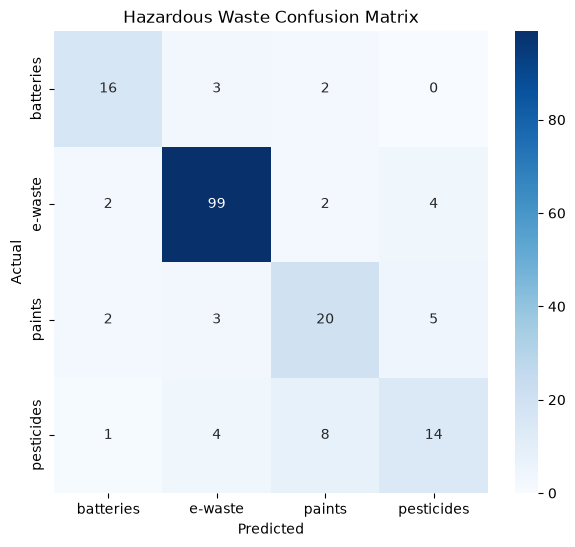

In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


predictions = hazardous_model.predict(val_data)


y_pred = np.argmax(
    predictions,
    axis=1
)


y_true = val_data.classes


cm = confusion_matrix(
    y_true,
    y_pred
)


plt.figure(figsize=(7,6))


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(val_data.class_indices.keys()),
    yticklabels=list(val_data.class_indices.keys())
)


plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Hazardous Waste Confusion Matrix")

plt.show()

In [16]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(val_data.class_indices.keys())
    )
)

              precision    recall  f1-score   support

   batteries       0.76      0.76      0.76        21
     e-waste       0.91      0.93      0.92       107
      paints       0.62      0.67      0.65        30
  pesticides       0.61      0.52      0.56        27

    accuracy                           0.81       185
   macro avg       0.73      0.72      0.72       185
weighted avg       0.80      0.81      0.80       185

